In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score
)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

In [3]:
df = pd.read_csv("creditcard.csv")

print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
print(df["Class"].value_counts())

Shape: (284807, 31)

First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21 

In [4]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [5]:
class_counts = df["Class"].value_counts()

fraud_count = class_counts[1]
non_fraud_count = class_counts[0]

print("Non-Fraud:", non_fraud_count)
print("Fraud:", fraud_count)

fraud_percentage = (fraud_count / len(df)) * 100
print(f"Fraud percentage: {fraud_percentage:.4f}%")

Non-Fraud: 284315
Fraud: 492
Fraud percentage: 0.1727%


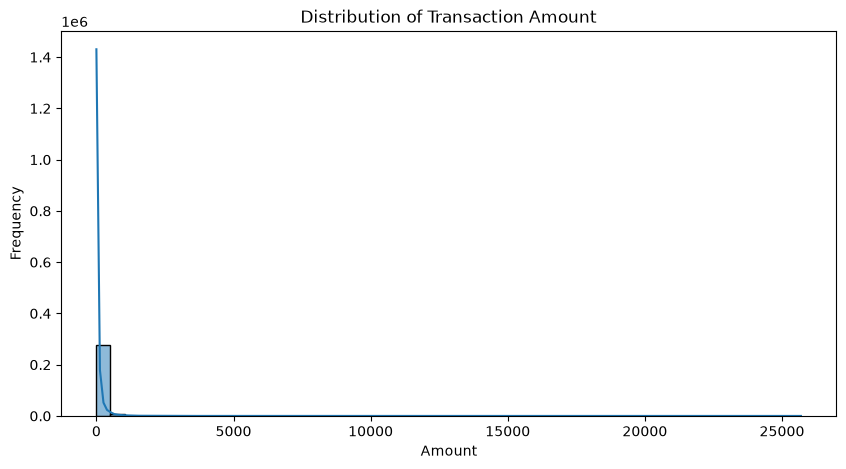

In [6]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Amount"], bins=50, kde=True)
plt.title("Distribution of Transaction Amount")
plt.xlabel("Amount")
plt.ylabel("Frequency")
plt.show()

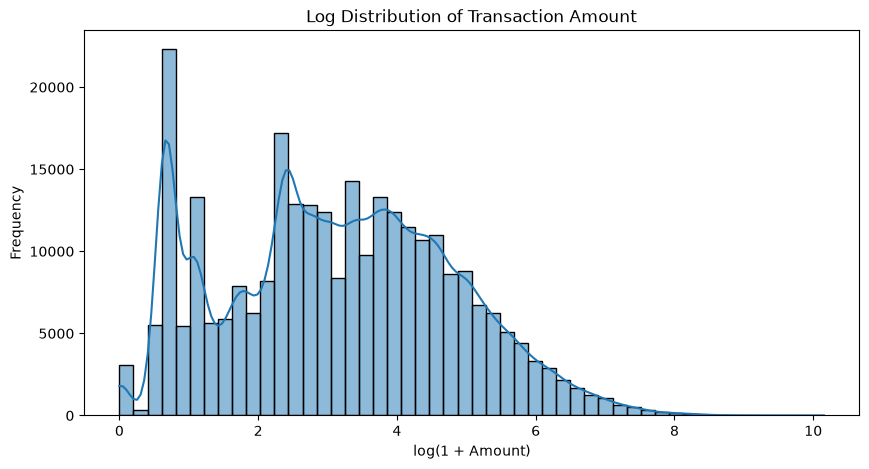

In [7]:
# Log tranformation to reduce skewness
plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(df["Amount"]), bins=50, kde=True)
plt.title("Log Distribution of Transaction Amount")
plt.xlabel("log(1 + Amount)")
plt.ylabel("Frequency")
plt.show()

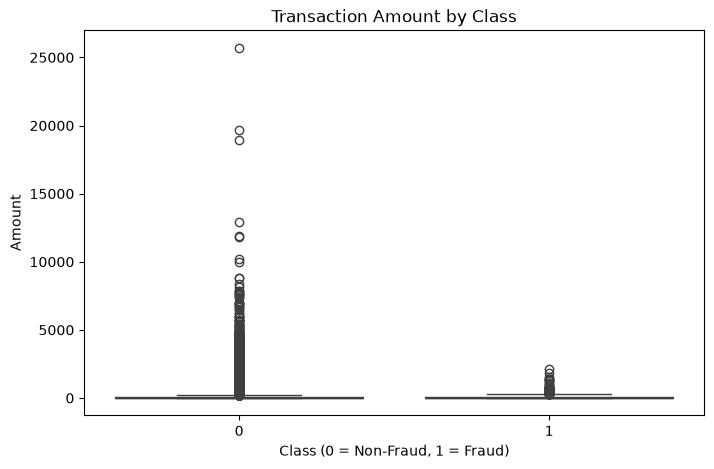

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="Class", y="Amount", data=df)
plt.title("Transaction Amount by Class")
plt.xlabel("Class (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Amount")
plt.show()

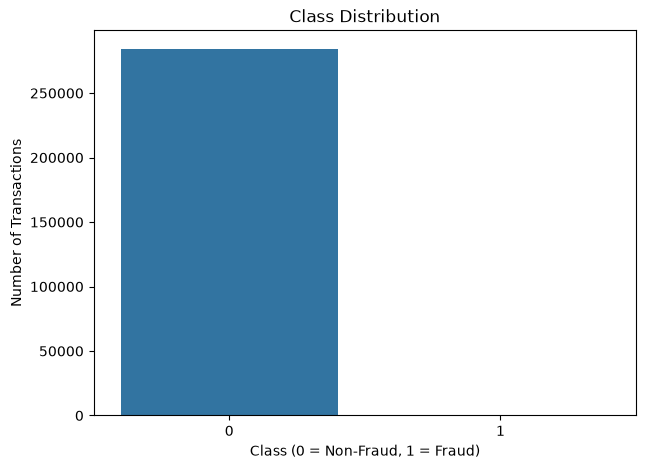

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(x="Class", data=df)

plt.title("Class Distribution")
plt.xlabel("Class (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

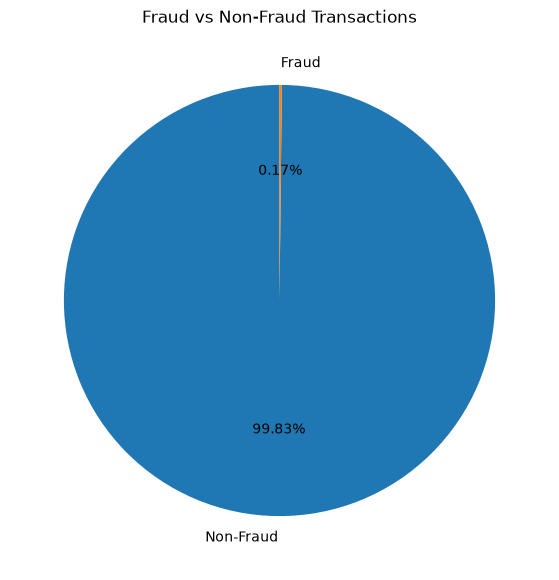

In [10]:
plt.figure(figsize=(7, 7))

plt.pie(
    class_counts,
    labels=["Non-Fraud", "Fraud"],
    autopct="%.2f%%",
    startangle=90
)

plt.title("Fraud vs Non-Fraud Transactions")
plt.show()

In [11]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nOriginal training distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training shape: (227845, 30)
Testing shape: (56962, 30)

Original training distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
rus = RandomUnderSampler(
    sampling_strategy="auto",
    random_state=42
)

X_train_rus, y_train_rus = rus.fit_resample(
    X_train_scaled,
    y_train
)

print("After Random Under-Sampling:")
print(pd.Series(y_train_rus).value_counts())

After Random Under-Sampling:
Class
0    394
1    394
Name: count, dtype: int64


In [15]:
model_rus = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_rus.fit(X_train_rus, y_train_rus)

y_pred_rus = model_rus.predict(X_test_scaled)

In [16]:
print("Random Under-Sampling Results")
print("--------------------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_rus))
print("Precision:", precision_score(y_test, y_pred_rus))
print("Recall   :", recall_score(y_test, y_pred_rus))
print("F1-score :", f1_score(y_test, y_pred_rus))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rus))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rus))

Random Under-Sampling Results
--------------------------------
Accuracy : 0.9602190934307082
Precision: 0.03833049403747871
Recall   : 0.9183673469387755
F1-score : 0.07358953393295176

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     56864
           1       0.04      0.92      0.07        98

    accuracy                           0.96     56962
   macro avg       0.52      0.94      0.53     56962
weighted avg       1.00      0.96      0.98     56962

Confusion Matrix:
[[54606  2258]
 [    8    90]]


In [17]:
ros = RandomOverSampler(
    sampling_strategy="auto",
    random_state=42
)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train_scaled,
    y_train
)

print("After Random Over-Sampling:")
print(pd.Series(y_train_ros).value_counts())

After Random Over-Sampling:
Class
0    227451
1    227451
Name: count, dtype: int64


In [18]:
model_ros = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_ros.fit(X_train_ros, y_train_ros)

y_pred_ros = model_ros.predict(X_test_scaled)

In [19]:
print("Random Over-Sampling Results")
print("--------------------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_ros))
print("Precision:", precision_score(y_test, y_pred_ros))
print("Recall   :", recall_score(y_test, y_pred_ros))
print("F1-score :", f1_score(y_test, y_pred_ros))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_ros))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_ros))

Random Over-Sampling Results
--------------------------------
Accuracy : 0.975667989185773
Precision: 0.06130790190735695
Recall   : 0.9183673469387755
F1-score : 0.11494252873563218

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

Confusion Matrix:
[[55486  1378]
 [    8    90]]


In [20]:
smote = SMOTE(
    sampling_strategy="auto",
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("After SMOTE:")
print(pd.Series(y_train_smote).value_counts())

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


In [21]:
model_smote = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = model_smote.predict(X_test_scaled)

In [22]:
print("SMOTE Results")
print("--------------------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_smote))
print("Precision:", precision_score(y_test, y_pred_smote))
print("Recall   :", recall_score(y_test, y_pred_smote))
print("F1-score :", f1_score(y_test, y_pred_smote))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_smote))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_smote))

SMOTE Results
--------------------------------
Accuracy : 0.9741055440469084
Precision: 0.057803468208092484
Recall   : 0.9183673469387755
F1-score : 0.10876132930513595

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962

Confusion Matrix:
[[55397  1467]
 [    8    90]]


In [23]:
results = pd.DataFrame({
    "Method": ["RUS", "ROS", "SMOTE"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_rus),
        accuracy_score(y_test, y_pred_ros),
        accuracy_score(y_test, y_pred_smote)
    ],
    "Precision": [
        precision_score(y_test, y_pred_rus),
        precision_score(y_test, y_pred_ros),
        precision_score(y_test, y_pred_smote)
    ],
    "Recall": [
        recall_score(y_test, y_pred_rus),
        recall_score(y_test, y_pred_ros),
        recall_score(y_test, y_pred_smote)
    ],
    "F1": [
        f1_score(y_test, y_pred_rus),
        f1_score(y_test, y_pred_ros),
        f1_score(y_test, y_pred_smote)
    ]
})

display(results)

,Method,Accuracy,Precision,Recall,F1
0,RUS,0.960219,0.038330,0.918367,0.073590
1,ROS,0.975668,0.061308,0.918367,0.114943
2,SMOTE,0.974106,0.057803,0.918367,0.108761


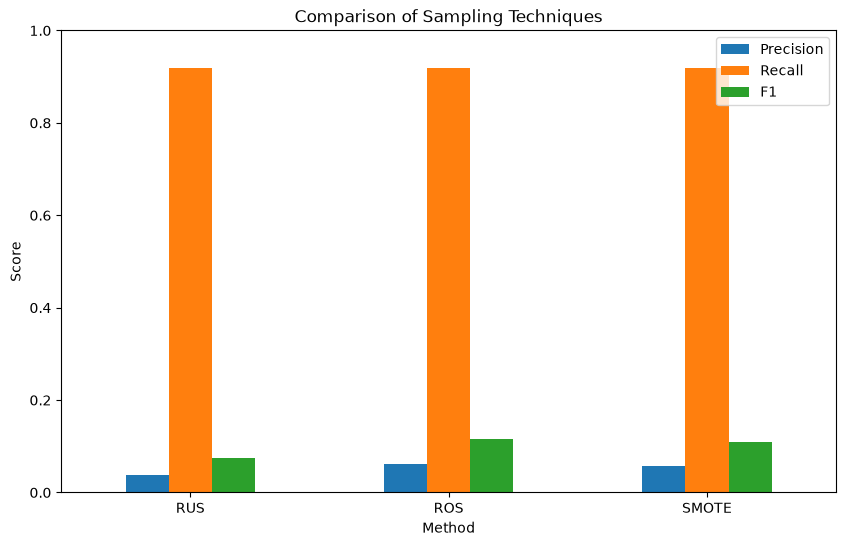

In [24]:
results.set_index("Method")[["Precision", "Recall", "F1"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Sampling Techniques")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

In [25]:
features = [col for col in df.columns if col != "Class"]

fraud_data = df[df["Class"] == 1]
normal_data = df[df["Class"] == 0]

test_results = []

for feature in features:

    stat, p_value = mannwhitneyu(
        normal_data[feature],
        fraud_data[feature],
        alternative="two-sided"
    )

    test_results.append({
        "Feature": feature,
        "U-statistic": stat,
        "p-value": p_value
    })

test_df = pd.DataFrame(test_results)

test_df = test_df.sort_values("p-value")

display(test_df.head(15))

,Feature,U-statistic,p-value
14,V14,132771289.0,1.471581e-260
4,V4,8636598.0,3.625904e-248
12,V12,131075998.0,8.416027e-247
11,V11,11458771.0,4.910592e-226
10,V10,127861066.0,9.611131e-222
3,V3,127583455.0,1.211048e-219
2,V2,20289296.0,1.650438e-163
16,V16,118499273.0,1.808172e-156
9,V9,118073844.0,8.943723e-154
7,V7,116915822.0,1.464234e-146


In [26]:
reject, corrected_p, _, _ = multipletests(
    test_df["p-value"],
    method="fdr_bh"
)

test_df["Adjusted p-value"] = corrected_p
test_df["Significant"] = reject

display(test_df)

,Feature,U-statistic,p-value,Adjusted p-value,Significant
14,V14,132771289.0,1.471581e-260,4.414742e-259,True
4,V4,8636598.0,3.625904e-248,5.438857e-247,True
12,V12,131075998.0,8.416027e-247,8.416027e-246,True
11,V11,11458771.0,4.910592e-226,3.682944e-225,True
10,V10,127861066.0,9.611131e-222,5.766679e-221,True
3,V3,127583455.0,1.211048e-219,6.055240e-219,True
2,V2,20289296.0,1.650438e-163,7.073304e-163,True
16,V16,118499273.0,1.808172e-156,6.780646e-156,True
9,V9,118073844.0,8.943723e-154,2.981241e-153,True
7,V7,116915822.0,1.464234e-146,4.392701e-146,True
